In [1]:
import pandas as pd

df = pd.read_csv("student_scores.csv")

df.head()

,hours_studied,exam_score
0,1.0,35
1,1.5,38
2,2.0,42
3,2.5,45
4,3.0,50


# Create virtual environment
python -m venv .venv

# Activate virtual environment
.\.venv\Scripts\Activate.ps1

# Upgrade pip
python -m pip install --upgrade pip

# Install Machine Learning packages
python -m pip install numpy pandas matplotlib seaborn scikit-learn jupyter ipykernel

# Save package versions
python -m pip freeze > requirements.txt

In [2]:
df.shape

(20, 2)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   hours_studied  20 non-null     float64
 1   exam_score     20 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 452.0 bytes


In [4]:
df.describe()

,hours_studied,exam_score
count,20.00000,20.000000
mean,5.75000,67.250000
std,2.95804,19.686691
min,1.00000,35.000000
25%,3.37500,51.500000
50%,5.75000,67.500000
75%,8.12500,83.500000
max,10.50000,98.000000


In [5]:
df.isnull().sum()

hours_studied    0
exam_score       0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

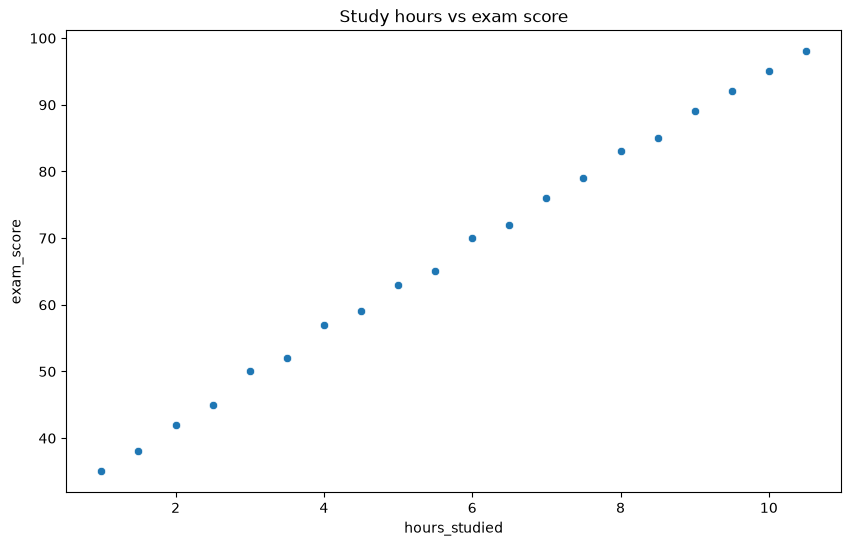

In [8]:
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df,
    x="hours_studied",
    y="exam_score"
)
plt.title("Study hours vs exam score")
plt.xlabel("hours_studied")
plt.ylabel("exam_score")
plt.show()

In [9]:
X=df[["hours_studied"]]
y=df["exam_score"]

In [10]:
X.shape

(20, 1)

In [11]:
y.shape

(20,)

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [14]:
X_train.shape, X_test.shape

((16, 1), (4, 1))

In [15]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[6.6]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['hours_studied']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,29.47
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [16]:
model.coef_

array([6.59840145])

In [17]:
model.intercept_

np.float64(29.465691449253498)

In [18]:
y_pred = model.predict(X_test)

y_pred

array([36.0640929 , 92.1505052 , 85.55210376, 39.36329362])

In [19]:
comparison = pd.DataFrame({
    "Actual Score": y_test,
    "Predicted Score": y_pred
})

comparison

,Actual Score,Predicted Score
0,35,36.064093
17,92,92.150505
15,85,85.552104
1,38,39.363294


In [20]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

In [21]:
pd.Series({
    "MAE": mae,
    "MSE": mse,
    "RMSE": rmse,
    "R2 Score": r2
})

MAE         0.782499
MSE         0.829583
RMSE        0.910815
R2 Score    0.998786
dtype: float64

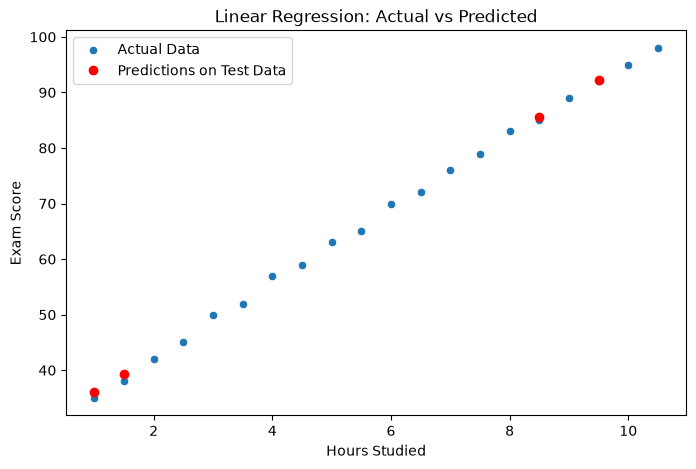

In [22]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="hours_studied",
    y="exam_score",
    label="Actual Data"
)

plt.plot(
    X_test["hours_studied"],
    y_pred,
    color="red",
    marker="o",
    linestyle="None",
    label="Predictions on Test Data"
)

plt.title("Linear Regression: Actual vs Predicted")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.legend()
plt.show()

In [23]:
new_student = pd.DataFrame({
    "hours_studied": [6.0]
})

model.predict(new_student)

array([69.05610014])

In [24]:
new_students = pd.DataFrame({
    "hours_studied": [2.0, 4.0, 6.0, 8.0, 10.0]
})

predictions = model.predict(new_students)

pd.DataFrame({
    "Hours Studied": new_students["hours_studied"],
    "Predicted Score": predictions
})

,Hours Studied,Predicted Score
0,2.0,42.662494
1,4.0,55.859297
2,6.0,69.056100
3,8.0,82.252903
4,10.0,95.449706


In [28]:
comparison = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})

comparison["Error"] = (
    comparison["Actual"] - comparison["Predicted"]
)

comparison["Absolute Error"] = comparison["Error"].abs()

comparison

,Actual,Predicted,Error,Absolute Error
0,35,36.064093,-1.064093,1.064093
1,92,92.150505,-0.150505,0.150505
2,85,85.552104,-0.552104,0.552104
3,38,39.363294,-1.363294,1.363294


In [29]:
df.head()

,hours_studied,exam_score
0,1.0,35
1,1.5,38
2,2.0,42
3,2.5,45
4,3.0,50


In [30]:
y_test

0     35
17    92
15    85
1     38
Name: exam_score, dtype: int64

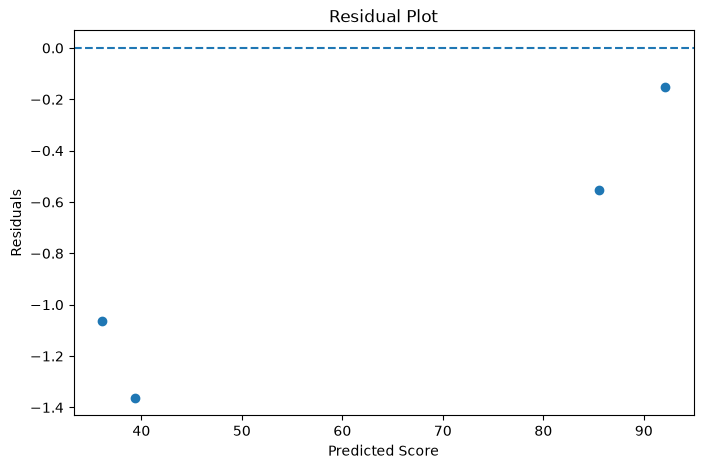

In [31]:
residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Score")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

In [33]:
residuals = y_test.to_numpy() - y_pred

comparison = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred,
    "Residual": residuals
})

comparison

,Actual,Predicted,Residual
0,35,36.064093,-1.064093
1,92,92.150505,-0.150505
2,85,85.552104,-0.552104
3,38,39.363294,-1.363294
